# H and D of each iteration from statevector simulation

$$
H^1 = 0.10658543\, II
     - 0.26276814\, IX
     - 0.42591697\, XI  + 0.10364115\, XX
     + 0.08623429\, ZI
     - 0.23846842\, ZX 
$$
  

Density in OAO basis: $D^1$:
\begin{bmatrix}
0.4759294  & 0.23749211 & 0.43914487 & 0.01303429 \\
0.23749211 & 0.47620558 & 0.01285079 & 0.43916532 \\
0.43914487 & 0.01285079 & 0.52416984 &-0.23749203 \\
0.01303429 & 0.43916532 &-0.23749203 & 0.52369519
\end{bmatrix}

 --------------------------------------------------

$$
H^2 =
0.1223350050\, II
- 0.2642415780\, IX
+ 0.0001097028\, IZ
- 0.4246506020\, XI
+ 0.1040782710\, XX
- 0.0000033944\, XZ
+ 0.0000003032\, YY
+ 0.0758960404\, ZI
- 0.2398195410\, ZX
- 0.0000765068\, ZZ
$$
  

Density in OAO basis: $D^2$:
\begin{bmatrix}
0.48564009 & 0.24193928 & 0.43726035 & 0.00790951 \\
0.24193928 & 0.48561452 & 0.00799556 & 0.43725795 \\
0.43726035 & 0.00799556 & 0.51431229 &-0.24193928 \\
0.00790951 & 0.43725795 &-0.24193928 & 0.51443309
\end{bmatrix}

 --------------------------------------------------

$$
H^3 =
0.1250140280\, II
- 0.2641253660\, IX
+ 0.0000161579\, IZ
- 0.4247400740\, XI
+ 0.1039192530\, XX
- 0.0000011404\, XZ
+ 0.0000003313\, YY
+ 0.0798526176\, ZI
- 0.2397743090\, ZX
- 0.0000167338\, ZZ
$$
  

 Density in OAO basis: $D^3$:
\begin{bmatrix}
0.4820981  & 0.24084761 & 0.43769377 & 0.00980395 \\
0.24084761 & 0.48221701 & 0.00983211 & 0.43769798 \\
0.43769377 & 0.00983211 & 0.51788641 &-0.24084762 \\
0.00980395 & 0.43769798 &-0.24084762 & 0.51779848
\end{bmatrix}

 --------------------------------------------------
 
$$
H^4 =
0.1250073290\, II
- 0.2641216850\, IX
+ 0.0000035496\, IZ
- 0.4247446350\, XI
+ 0.1039183490\, XX
- 0.0000015862\, XZ
+ 0.0000006970\, YY
+ 0.0798906623\, ZI
- 0.2397709510\, ZX
- 0.0000159319\, ZZ
$$
  
 Density in OAO basis: $D^4$:
\begin{bmatrix}
0.48215912 & 0.24086493 & 0.43768692 & 0.00979544 \\
0.24086493 & 0.48206822 & 0.00989086 & 0.43768106 \\
0.43768692 & 0.00989086 & 0.51778836 &-0.24086492 \\
0.00979544 & 0.43768106 &-0.24086492 & 0.51798429
\end{bmatrix}

 --------------------------------------------------


In [1]:
import numpy as np
import scipy as sp
from pyscf import gto, scf
import perceval as pcvl
from qiskit.quantum_info import Pauli, PauliList, Statevector, SparsePauliOp, Operator
from qlass.quantum_chemistry.hamiltonians import transformation_Hmatrix_Hqubit, sparsepauliop_dictionary
from qlass.vqe.ansatz import list_of_ones
from qlass.utils import photon_to_qubit_unitary
from qiskit.circuit.library import n_local
from perceval.algorithm import Sampler
from qiskit import QuantumCircuit, transpile
from perceval.converters import QiskitConverter
from perceval.components import catalog
from perceval.simulators import Simulator
from perceval import BasicState
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import warnings
warnings.filterwarnings('ignore')

/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/arajamani/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


In [2]:
def circuit(nqubit, n_states, lp, layers=1):
    initial_circuits = []

    if nqubit is None:
        num_qubits = 2
    else:
        num_qubits = nqubit
    for _i in range(n_states):
        initial_circuits += [QuantumCircuit(num_qubits)]
    """Initial states"""
    for state in range(n_states):  # binarystring representation of the integer
        for i in list_of_ones(state, num_qubits):
            initial_circuits[state].x(i)

    circuits = []
    for state in range(n_states):
        ansatz = n_local(
            num_qubits=num_qubits,
            rotation_blocks="ry",
            entanglement_blocks="cx",
            entanglement="linear",
            reps=layers,
            insert_barriers=False,
        )
        # Prepend the initial state
        circuit = QuantumCircuit(num_qubits)
        circuit.compose(initial_circuits[state], inplace=True)
        circuit.compose(ansatz, inplace=True)
        circuits.append(circuit)

    """Assign parameters"""
    intial_states = []
    for c in range(len(initial_circuits)):
        sv = Statevector.from_instruction(initial_circuits[c])
        index = list(sv.data).index(1 + 0j)  # position of the "1"
        bitstring = format(index, f"0{sv.num_qubits}b")
        bits_list = [int(b) for b in bitstring]
        intial_states.append(pcvl.LogicalState(bits_list))
    circuits = [c.assign_parameters(lp) for c in circuits]
    ansatz_transpiled = [
        transpile(c, basis_gates=["u3", "cx"], optimization_level=3) for c in circuits
    ]
    q_converter = QiskitConverter(backend_name="SLOS")
    processors = [q_converter.convert(at, use_postselection=True) for at in ansatz_transpiled]

    p_processors = [p.with_input(input_state=ist) for p, ist in zip(processors, intial_states, strict=False)]

    return processors

In [3]:
def mesurements(H, proc, nshots=1024):
    e = 0.
    for pauli_str, coeff in zip(H.keys(), H.values()):
        # Convert pauli_str to a standard string if it's a Qiskit object
        p_str = str(pauli_str)

        # Call the expectation function for ONE string at a time
        term_expectation = get_pauli_expectation(proc, p_str, nshots)
        e += coeff.real * term_expectation

    return e.real

In [4]:
def get_pauli_expectation(p, pauli_str, nshots=1024):
    """
    Computes the expectation value of a single Pauli string (e.g., 'ZX')
    by rotating the basis and simulating shots.
    """
    backend = p.backend
    cir = p.linear_circuit()
    int_st = p.input_state
    # Create a copy of the circuit to append measurement rotations
    c = cir.copy()

    # Apply rotations to the modes to measure in the X or Y basis
    for i, char in enumerate(pauli_str):
        mode_0 = i * 2
        mode_1 = i * 2 + 1
        if char == 'X':
            # Beam Splitter acts as a Hadamard for dual-rail
            c.add((mode_0, mode_1), pcvl.BS.H())
        elif char == 'Y':
            c.add(mode_0, pcvl.PS(np.pi / 2))
            c.add((mode_0, mode_1), pcvl.BS.H())

    # Simulate the distribution

    backend.set_circuit(c)
    backend.set_input_state(input_state=int_st)

    full_dist = backend.prob_distribution()
    states, probs_list, ev_list = [], [], []

    for state, prob in full_dist.items():
        # 2. POST-SELECTION:
        # Check if physical modes (0-3) have exactly 1 photon per pair
        # AND check if auxiliary modes (4-5) match the expected ancilla state
        # (Usually ancillas must end in a specific state for the gate to succeed)

        condition_q0 = (state[0] + state[1] == 1)
        condition_q1 = (state[2] + state[3] == 1)

        # If your CX gate requires the ancilla to be in a specific state, add it here:
        # condition_ancilla = (state[4] == 0 and state[5] == 1)

        if condition_q0 and condition_q1:
            states.append(state)
            probs_list.append(prob)

            # 3. EIGENVALUE CALCULATION (Physical Modes Only)
            current_ev = 1
            for i, char in enumerate(pauli_str):

                if str(char) != "I":
                    # Only look at modes 0,1 or 2,3
                    val = 1 if state[i * 2] == 1 else -1
                    current_ev *= val
            ev_list.append(current_ev)
    probs = np.array(probs_list) / sum(probs_list)
    counts = np.random.multinomial(nshots, probs)

    return np.sum(counts * np.array(ev_list)) / nshots

In [5]:
def reconstruct_density_matrix(p, n_qubits=2, nshots=1024):
    """
    Reconstruct density using quantum state tomography
    """
    import itertools
    # Define the Pauli matrices
    I = np.eye(2, dtype=complex)
    X = np.array([[0, 1], [1, 0]], dtype=complex)
    Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
    Z = np.array([[1, 0], [0, -1]], dtype=complex)

    pauli_map = {'I': I, 'X': X, 'Y': Y, 'Z': Z}
    dim = 2 ** n_qubits
    rho = np.zeros((dim, dim), dtype=complex)

    # Generate all possible Pauli strings (e.g., 'II', 'IX', ...)
    bases = ['I', 'X', 'Y', 'Z']
    pauli_strings = [''.join(p) for p in itertools.product(bases, repeat=n_qubits)]

    for s in pauli_strings:
        # Get <P>
        exp_val = get_pauli_expectation(p, s, nshots=nshots)

        # Compute the Kronecker product for the Pauli matrix P
        p_matrix = pauli_map[s[0]]
        for char in s[1:]:
            p_matrix = np.kron(p_matrix, pauli_map[char])

        # Add to the sum: rho = 1/2^n * sum(<P> * P)
        rho += exp_val * p_matrix

    return rho / dim

In [6]:
def _callback(param, H):
    c = cost_function(param, H)
    processors = circuit(2, 2, layers=1, lp=param)
    orb_1 = mesurements(H, processors[0])
    orb_2 = mesurements(H, processors[1])
    cost.append(c)
    EA.append(orb_1)
    EB.append(orb_2)

In [7]:
def cost_function(param, H, nshots=1024):
    processors = circuit(2, 2, layers=1, lp=param)
    w = []
    for i in range(len(processors)):
        w.append(1 / (len(processors) ** 2) * (2 * len(processors) - 1 - 2 * i))
    cost = 0.
    tr = 0.
    for i, p in enumerate(processors):
        e = 0.
        for pauli_str, coeff in zip(H.keys(), H.values()):
            # Convert pauli_str to a standard string if it's a Qiskit object
            p_str = str(pauli_str)

            # Call the expectation function for ONE string at a time
            term_expectation = get_pauli_expectation(p, p_str, nshots)
            e += coeff.real * term_expectation
        cost += w[i] * e.real
        tr += e.real
    return cost

In [8]:
def pauli_string_to_matrix(pauli_string: str) -> np.ndarray:
    """
    Convert a Pauli string to a matrix representation.

    Args:
        pauli_string (str): A string of Pauli operators (I, X, Y, Z)

    Returns:
        np.ndarray: Matrix representation of the Pauli string

    """

    res: np.ndarray = np.array([[1.0]])

    # Define the Pauli matrices.
    I_pauli = np.eye(2)
    X = np.array([[0, 1], [1, 0]])
    Y = np.array([[0, -1.0j], [1.0j, 0]])
    Z = np.array([[1, 0], [0, -1]])

    for c in pauli_string:
        if c == "X":
            res = np.kron(res, X)
        elif c == "Y":
            res = np.kron(res, Y)
        elif c == "Z":
            res = np.kron(res, Z)
        else:
            res = np.kron(res, I_pauli)

    return res
    
def hamiltonian_matrix(H: dict[str, float]) -> np.ndarray:
    """
    Convert a Hamiltonian dictionary to a matrix representation.

    Args:
        H (Dict[str, float]): Hamiltonian dictionary

    Returns:
        np.ndarray: Matrix representation of the Hamiltonian

    """

    coeffs = list(H.values())
    matrices = [
        coeff * pauli_string_to_matrix(pauli_string)
        for pauli_string, coeff in zip(H.keys(), coeffs, strict=False)
    ]

    result: np.ndarray = np.sum(matrices, axis=0)
    return result

In [9]:
def plot_density(density, title="Electron Density"):
    plt.figure(figsize=(6,5))
    plt.imshow(density, cmap="plasma")
    for i in range(density.shape[0]):
        for j in range(density.shape[1]):
            plt.text(j, i, f"{density[i, j]:.6f}", ha='center', va='center', color='red')
    plt.colorbar(label="Density")
    plt.title(title)
    plt.xlabel(r"$x_2$ grid index")
    plt.ylabel(r"$x_1$ grid index")
    plt.show()

In [10]:
def plot_vqe(cost, EA, EB, E0, E1, iteration):
    trace = np.add(EA, EB)
    energy_classic = E0 + E1
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(cost, label="cost")
    ax.plot(EA, label=r"$E_A$")
    ax.plot(EB, label=r"$E_B$")
    ax.axhline(y=E0, ls="--", color="red", label=r"$E_0$")
    ax.axhline(y=E1, ls="--", color="green", label=r"$E_1$")
    ax.set_ylabel('Energy (hartree)', fontsize=16)
    ax.set_xlabel('VQE Iteration', fontsize=16)
    ax.tick_params(axis='both', labelsize=16)
    ax.legend(fontsize=16, loc="lower left")
    ax.set_title(f"ensemble VQE | SCF iteration: {iteration}", fontsize=16)
    sub_ax = inset_axes(
        parent_axes=ax,
        width="40%",
        height="40%",
        borderpad=1  # padding between parent and inset axes
    )
    sub_ax.plot(trace - energy_classic, color="green", label="error")
    sub_ax.set_yscale('log')
    sub_ax.set_ylabel('Error (hartree)', fontsize=16)
    sub_ax.set_xlabel('Iteration', fontsize=16)
    sub_ax.tick_params(axis='both', labelsize=16)
    sub_ax.legend(fontsize=16)
    plt.show()

## Iteration 1
$$
H^1 = 0.10658543\, II
     - 0.26276814\, IX
     - 0.42591697\, XI  + 0.10364115\, XX
     + 0.08623429\, ZI
     - 0.23846842\, ZX 
$$

In [11]:
# Iteration 1
shots = 1000000000
n_qubits = 2
n_occ = 2 # number of occupied states
params = np.random.rand(4)
dim = 2 ** n_qubits
cost, EA, EB = [], [], []
H_1 = {'II': 0.10658543, 'IX': -0.26276814, 'XI': -0.42591697, 'XX': 0.10364115, 'ZI': 0.08623429, 'ZX': -0.23846842}
print(f"number of shots: {shots:e}")

number of shots: 1.000000e+09


In [12]:
res = sp.optimize.minimize(cost_function, x0=params, args=(H_1, shots), method='COBYLA', callback=lambda p:_callback(p, H_1))

In [13]:
optimized_parameters = res.x
processors = circuit(2, 2, layers=1, lp=optimized_parameters)
trH = 0.
rho = np.zeros((dim, dim), dtype=complex)
for state in range(n_occ):
    trH += mesurements(H_1, processors[state], shots)
    rho += reconstruct_density_matrix(processors[state], n_qubits, shots)
H_matrix = hamiltonian_matrix(H_1)
diag_H = np.sort(np.linalg.eigvals(H_matrix))

print(f"Trace from VQE: {trH} | Trace from Exact: {np.sum(diag_H[:2])} | error: {abs(trH - np.sum(diag_H[:2]))}")

Trace from VQE: -0.7643663565260189 | Trace from Exact: -0.7644307935272299 | error: 6.443700121094853e-05


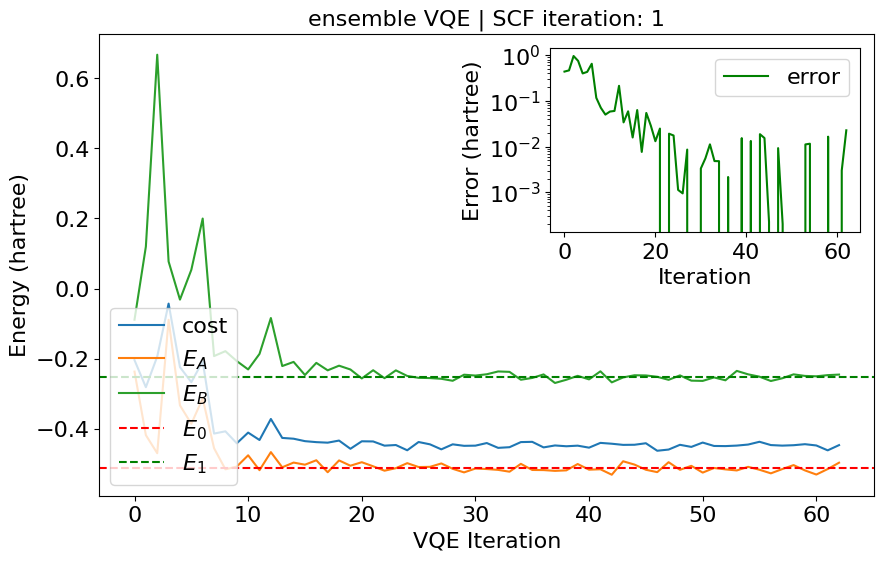

In [14]:
plot_vqe(cost, EA ,EB, diag_H[0], diag_H[1], 1)

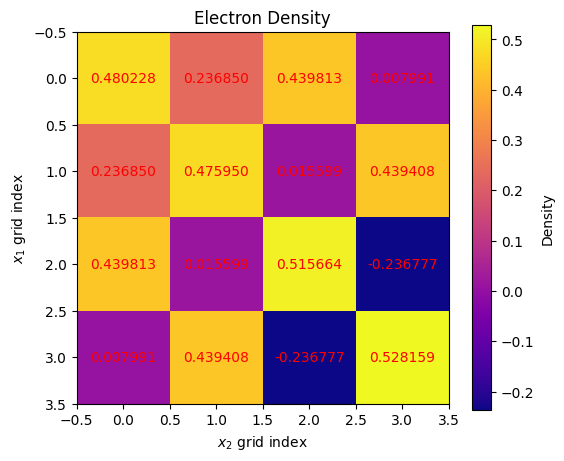

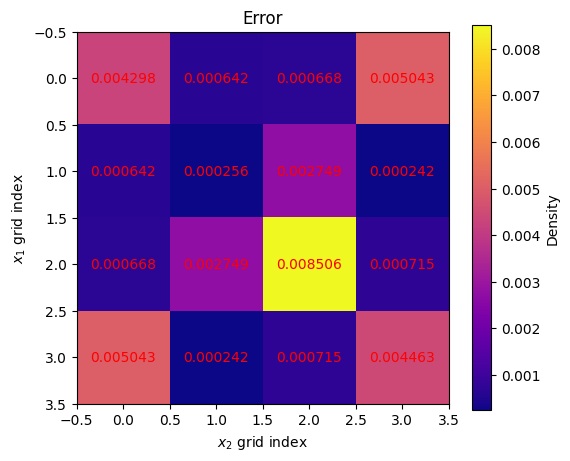

In [15]:
D_1 = np.array([[0.4759294, 0.23749211, 0.43914487, 0.01303429],
[0.23749211, 0.47620558, 0.01285079, 0.43916532],
[0.43914487, 0.01285079, 0.52416984,-0.23749203],
[0.01303429, 0.43916532,-0.23749203, 0.52369519]]) # from statevector simulation
error_D1 = np.abs(D_1 - rho.real)
plot_density(rho.real)
plot_density(error_D1, "Error")

## Iteration 2
$$ H^2 =
0.1223350050\, II
- 0.2642415780\, IX
+ 0.0001097028\, IZ
- 0.4246506020\, XI
+ 0.1040782710\, XX
- 0.0000033944\, XZ
+ 0.0000003032\, YY
+ 0.0758960404\, ZI
- 0.2398195410\, ZX
- 0.0000765068\, ZZ
$$

In [16]:
# Iteration 2
shots = 1000000000
n_qubits = 2
n_occ = 2 # number of occupied states
params = np.random.rand(4)
dim = 2 ** n_qubits
cost, EA, EB = [], [], []
H_2 = {"II": 0.1223350050, "IX": -0.2642415780, "IZ": 0.0001097028, "XI": -0.4246506020, "XX": 0.1040782710, "XZ": -0.0000033944, "YY": 0.0000003032, "ZI": 0.0758960404, "ZX": -0.2398195410, "ZZ": -0.0000765068}
print(f"number of shots: {shots:e}")

number of shots: 1.000000e+09


In [17]:
res = sp.optimize.minimize(cost_function, x0=params, args=(H_2, shots), method='COBYLA', callback=lambda p:_callback(p, H_2))

In [18]:
optimized_parameters = res.x
processors = circuit(2, 2, layers=1, lp=optimized_parameters)
trH = 0.
rho = np.zeros((dim, dim), dtype=complex)
for state in range(n_occ):
    trH += mesurements(H_2, processors[state], shots)
    rho += reconstruct_density_matrix(processors[state], n_qubits, shots)
H_matrix = hamiltonian_matrix(H_2)
diag_H = np.sort(np.linalg.eigvals(H_matrix))

print(f"Trace from VQE: {trH} | Trace from Exact: {np.sum(diag_H[:2])} | error: {abs(trH - np.sum(diag_H[:2]))}")

Trace from VQE: -0.7311329322984125 | Trace from Exact: (-0.7311991311018121+0j) | error: 6.61988033996419e-05


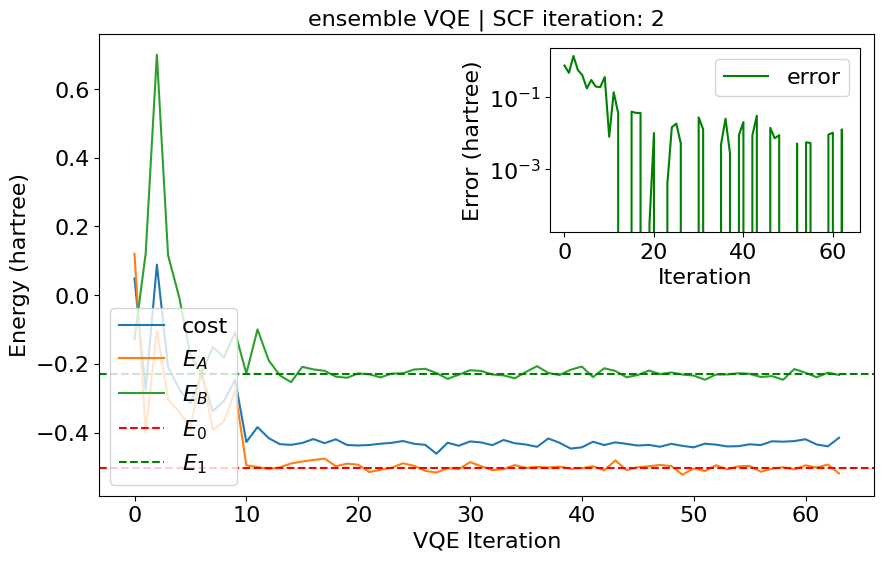

In [19]:
plot_vqe(cost, EA ,EB, diag_H[0], diag_H[1], 2)

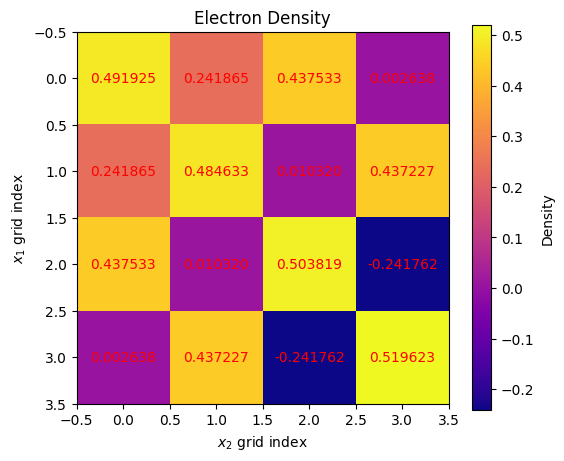

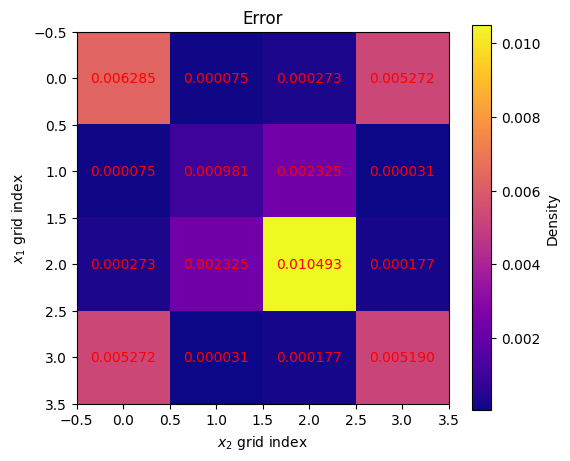

In [20]:
D_2 = np.array([[0.48564009, 0.24193928, 0.43726035, 0.00790951],
[0.24193928, 0.48561452, 0.00799556, 0.43725795],
[0.43726035, 0.00799556, 0.51431229,-0.24193928],
[0.00790951, 0.43725795,-0.24193928, 0.51443309]])
error_D2 = np.abs(D_2 - rho.real)
plot_density(rho.real)
plot_density(error_D2, "Error")

## Iteratoin 3
$$
H^3 =
0.1250140280\, II
- 0.2641253660\, IX
+ 0.0000161579\, IZ
- 0.4247400740\, XI
+ 0.1039192530\, XX
- 0.0000011404\, XZ
+ 0.0000003313\, YY
+ 0.0798526176\, ZI
- 0.2397743090\, ZX
- 0.0000167338\, ZZ
$$

In [21]:
# Iteration 3
shots = 1000000000
n_qubits = 2
n_occ = 2 # number of occupied states
params = np.random.rand(4)
dim = 2 ** n_qubits
cost, EA, EB = [], [], []
H_3 = {"II":0.1250140280, "IX":- 0.2641253660, "IZ": 0.0000161579, "XI": - 0.4247400740, "XX":0.1039192530, "XZ":- 0.0000011404, "YY": 0.0000003313, "ZI":+ 0.0798526176, "ZX":- 0.2397743090, "ZZ":- 0.0000167338}
print(f"number of shots: {shots:e}")

number of shots: 1.000000e+09


In [22]:
res = sp.optimize.minimize(cost_function, x0=params, args=(H_3, shots), method='COBYLA', callback=lambda p:_callback(p, H_3))

In [23]:
optimized_parameters = res.x
processors = circuit(2, 2, layers=1, lp=optimized_parameters)
trH = 0.
rho = np.zeros((dim, dim), dtype=complex)
for state in range(n_occ):
    trH += mesurements(H_3, processors[state], shots)
    rho += reconstruct_density_matrix(processors[state], n_qubits, shots)
H_matrix = hamiltonian_matrix(H_3)
diag_H = np.sort(np.linalg.eigvals(H_matrix))

print(f"Trace from VQE: {trH} | Trace from Exact: {np.sum(diag_H[:2])} | error: {abs(trH - np.sum(diag_H[:2]))}")

Trace from VQE: -0.7261067042993515 | Trace from Exact: (-0.726214080280602+0j) | error: 0.0001073759812504349


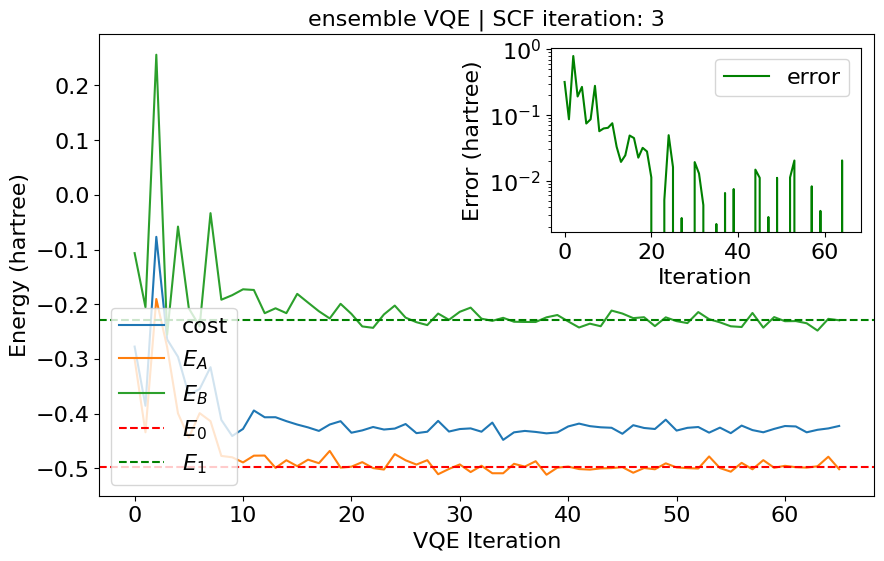

In [24]:
plot_vqe(cost, EA ,EB, diag_H[0], diag_H[1], 3)

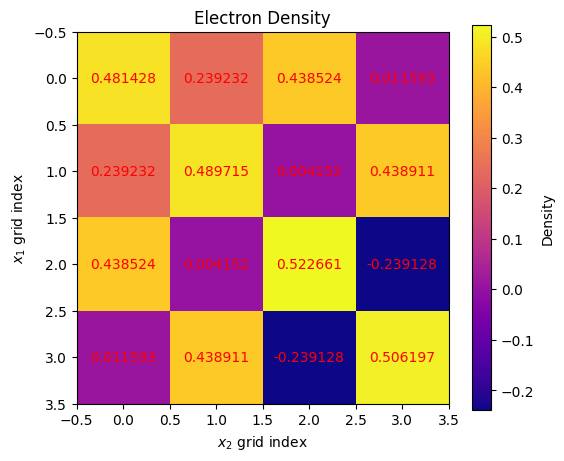

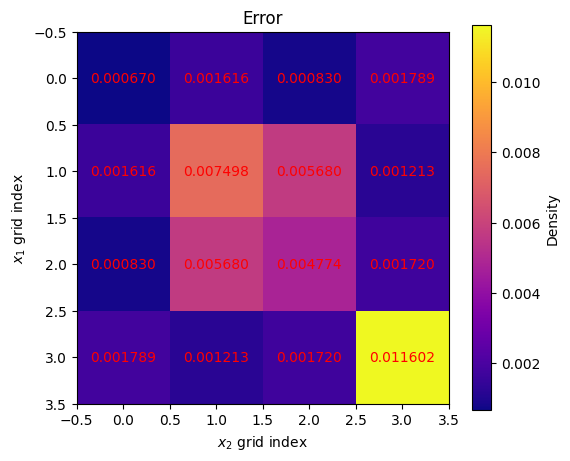

In [25]:
D_3 = np.array([[0.4820981, 0.24084761, 0.43769377, 0.00980395],
[0.24084761, 0.48221701, 0.00983211, 0.43769798],
[0.43769377, 0.00983211, 0.51788641,-0.24084762],
[0.00980395, 0.43769798,-0.24084762, 0.51779848]])
error_D3 = np.abs(D_3 - rho.real)
plot_density(rho.real)
plot_density(error_D3, "Error")

## Iteration 4
$$
H^4 =
0.1250073290\, II
- 0.2641216850\, IX
+ 0.0000035496\, IZ
- 0.4247446350\, XI
+ 0.1039183490\, XX
- 0.0000015862\, XZ
+ 0.0000006970\, YY
+ 0.0798906623\, ZI
- 0.2397709510\, ZX
- 0.0000159319\, ZZ
$$

In [26]:
# Iteration 4
shots = 1000000000
n_qubits = 2
n_occ = 2 # number of occupied states
params = np.random.rand(4)
dim = 2 ** n_qubits
cost, EA, EB = [], [], []
H_4 = {"II": 0.1250073290, "IX": -0.2641216850, "IZ": 0.0000035496, "XI": -0.4247446350, "XX": 0.1039183490, "XZ": -0.0000015862, "YY": 0.0000006970, "ZI": 0.0798906623, "ZX": -0.2397709510, "ZZ": -0.0000159319}
print(f"number of shots: {shots:e}")

number of shots: 1.000000e+09


In [27]:
res = sp.optimize.minimize(cost_function, x0=params, args=(H_4, shots), method='COBYLA', callback=lambda p:_callback(p, H_4))

In [28]:
optimized_parameters = res.x
processors = circuit(2, 2, layers=1, lp=optimized_parameters)
trH = 0.
rho = np.zeros((dim, dim), dtype=complex)
for state in range(n_occ):
    trH += mesurements(H_4, processors[state], shots)
    rho += reconstruct_density_matrix(processors[state], n_qubits, shots)
H_matrix = hamiltonian_matrix(H_4)
diag_H = np.sort(np.linalg.eigvals(H_matrix))

print(f"Trace from VQE: {trH} | Trace from Exact: {np.sum(diag_H[:2])} | error: {abs(trH - np.sum(diag_H[:2]))}")

Trace from VQE: -0.7261917983055939 | Trace from Exact: (-0.726234976770672+0j) | error: 4.317846507806422e-05


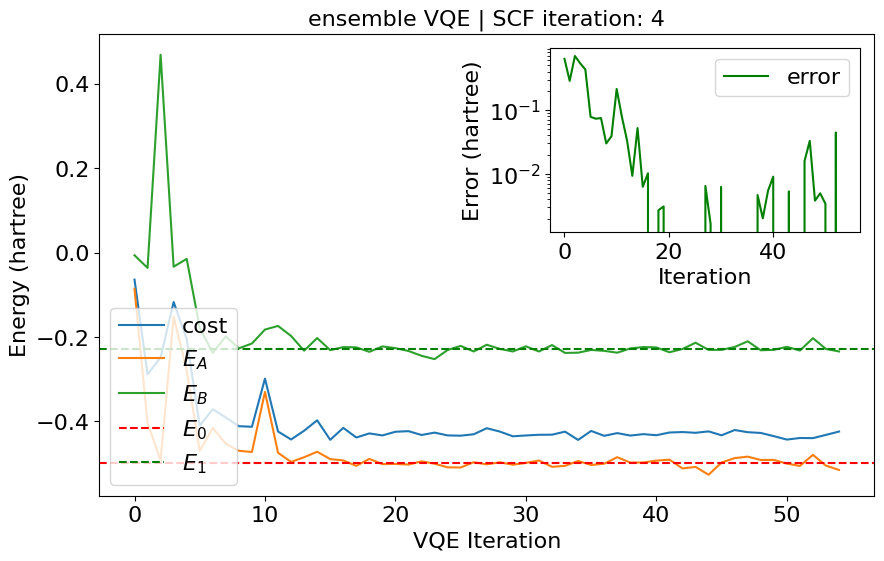

In [29]:
plot_vqe(cost, EA ,EB, diag_H[0], diag_H[1], 4)

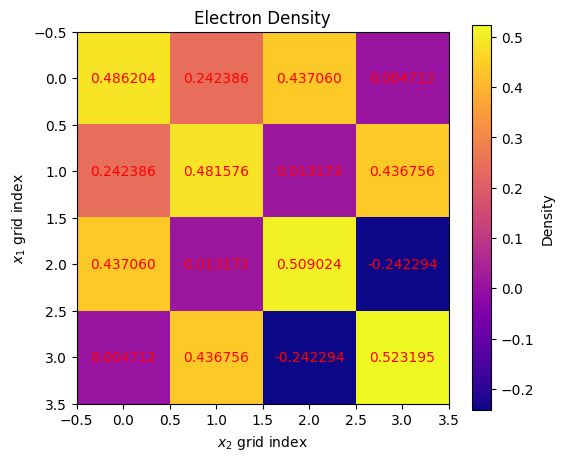

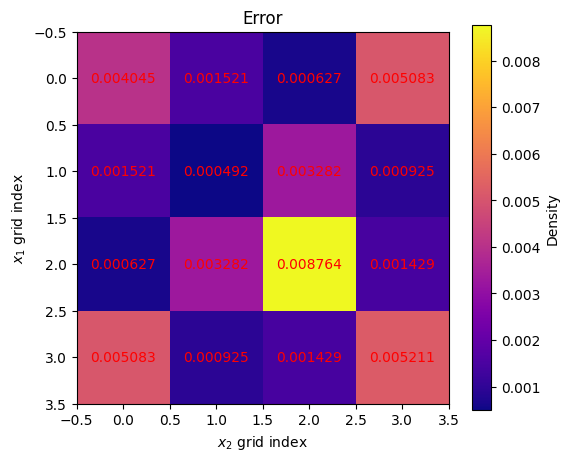

In [30]:
D_4 = np.array([[0.48215912, 0.24086493,  0.43768692,  0.00979544],
[0.24086493, 0.48206822, 0.00989086, 0.43768106],
[0.43768692, 0.00989086, 0.51778836, -0.24086492],
[0.00979544, 0.43768106, -0.24086492, 0.51798429]])
error_D4 = np.abs(D_4 - rho.real)
plot_density(rho.real)
plot_density(error_D4, "Error")